# Sales Forecasting — PT Graha Material Nusantara

Notebook ini menyiapkan **beberapa opsi model peramalan penjualan** agar tim dashboard dapat
memilih sendiri model dan horizon yang ditampilkan. Tiga seri diramalkan: **omzet**, **jumlah
pesanan**, dan **volume barang**. Setiap model diuji dengan *rolling-origin backtest* 12 bulan,
lalu meramal 12 bulan ke depan (Nov 2026–Okt 2027) beserta interval 80% dan 95%.

Prinsip yang dijaga:

- Omzet hanya dari pesanan `Selesai`; retur dan pembatalan tidak dihitung sebagai penjualan.
- Harga memakai `harga_satuan_bersih` hasil koreksi notebook churn (bug pemisah ribuan).
- Model dipilih dari data, bukan diasumsikan: baseline seasonal naive selalu ikut dibandingkan.
- Metrik utama **WAPE** karena lebih stabil daripada MAPE ketika nilai aktual kecil.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib

if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.ticker import FuncFormatter, PercentFormatter
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

AKAR_NOTEBOOK = Path.cwd().resolve()
if not (AKAR_NOTEBOOK / "src").exists():
    AKAR_NOTEBOOK = AKAR_NOTEBOOK.parent
sys.path.insert(0, str(AKAR_NOTEBOOK))

from src.graha import (
    AKHIR_DATA,
    FORECAST_DIR,
    GAMBAR_DIR,
    PALET,
    atur_gaya,
    muat_transaksi,
    rupiah,
    siapkan_folder,
    simpan,
)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
atur_gaya()
siapkan_folder()
SEED = 42
np.random.seed(SEED)

## 0. Seri bulanan

Data bersih berakhir 31 Oktober 2026, jadi tersedia 94 bulan penuh (Jan 2019–Okt 2026).
Tabel analitik hasil notebook churn dipakai agar angka omzet identik dengan bagian churn.

In [2]:
berkas_analitik = AKAR_NOTEBOOK / "data" / "processed" / "transaksi_analitik.csv"
if berkas_analitik.exists():
    transaksi = pd.read_csv(
        berkas_analitik, parse_dates=["tanggal_transaksi", "tanggal_kirim"]
    )
else:
    transaksi = muat_transaksi()

selesai = transaksi[transaksi["status_pesanan"] == "Selesai"].copy()
selesai["periode"] = selesai["tanggal_transaksi"].dt.to_period("M")

seri = pd.DataFrame(
    {
        "omzet": selesai.groupby("periode")["omzet"].sum(),
        "pesanan": selesai.groupby("periode")["nomor_pesanan"].nunique(),
        "volume": selesai.groupby("periode")["jumlah"].sum(),
    }
)
seri.index = seri.index.to_timestamp("M")
seri = seri.asfreq("ME")
seri.index.name = "bulan"

print(f"periode: {seri.index.min().date()} s.d. {seri.index.max().date()} ({len(seri)} bulan)")
print(f"bulan kosong: {int(seri.isna().any(axis=1).sum())}")
ringkas_seri = pd.DataFrame(
    {
        "nilai": ["omzet", "pesanan", "volume"],
        "total": [rupiah(seri["omzet"].sum()), f"{seri['pesanan'].sum():,.0f}", f"{seri['volume'].sum():,.0f}"],
        "rata2_bulanan": [
            rupiah(seri["omzet"].mean()),
            f"{seri['pesanan'].mean():,.0f}",
            f"{seri['volume'].mean():,.0f}",
        ],
    }
)
ringkas_seri

periode: 2019-01-31 s.d. 2026-10-31 (94 bulan)
bulan kosong: 0


,nilai,total,rata2_bulanan
0,omzet,Rp 38.41 M,Rp 408.7 jt
1,pesanan,"7,454",79
2,volume,"710,716","7,561"


In [3]:
tahunan = selesai.groupby(selesai["tanggal_transaksi"].dt.year).agg(
    omzet=("omzet", "sum"), pesanan=("nomor_pesanan", "nunique")
)
tahunan["omzet"] = tahunan["omzet"].map(rupiah)
tahunan

,omzet,pesanan
tanggal_transaksi,,
2019,Rp 4.06 M,811
2020,Rp 3.50 M,766
2021,Rp 4.55 M,949
2022,Rp 5.25 M,1078
2023,Rp 5.67 M,1147
2024,Rp 6.09 M,1136
2025,Rp 5.30 M,927
2026,Rp 4.00 M,640


## 1. Pola musiman dan dekomposisi

STL memisahkan trend, musim, dan sisa. Musim yang kuat berarti horizon 12 bulan masih masuk akal;
trend yang berbalik pada 2024–2026 menjelaskan mengapa model dengan tren linear akan melebih-lebihkan.

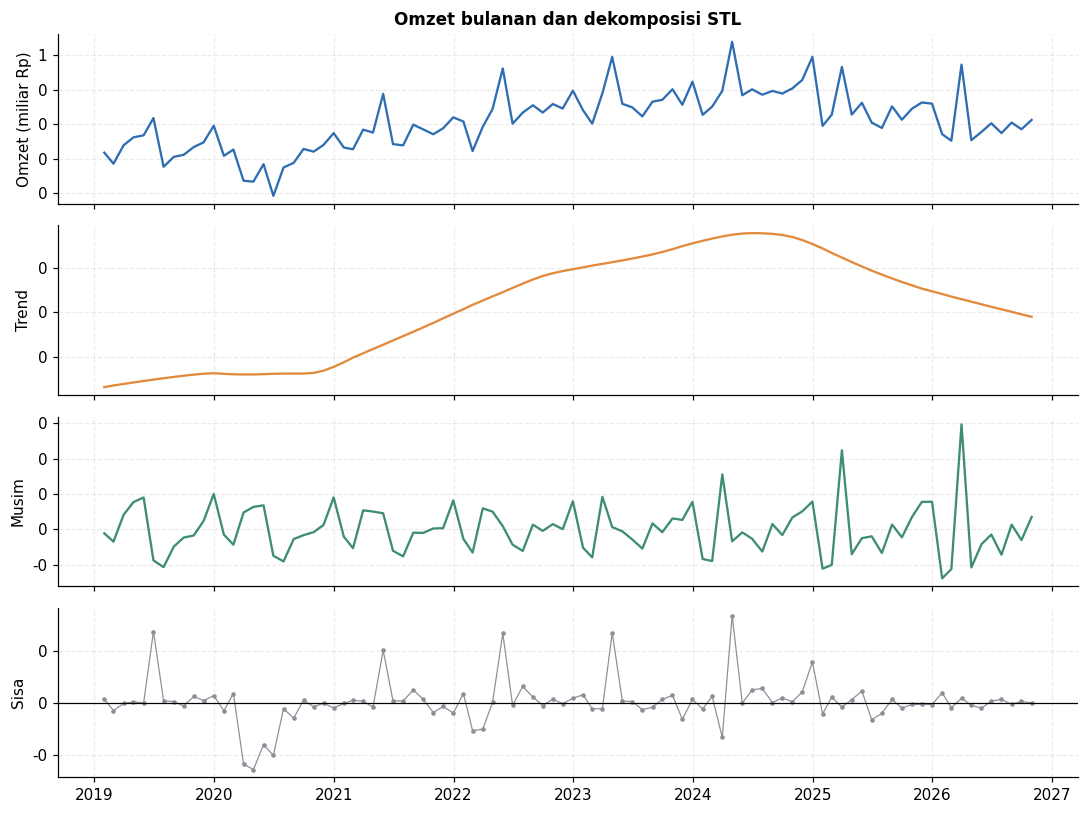

  tersimpan: data\processed\forecast\forecast_seasonality.csv (12 baris)


,omzet,pesanan,volume
bulan,,,
1,0.93,0.91,0.86
2,0.91,0.88,0.91
3,1.06,1.01,1.06
4,1.04,1.00,0.96
5,1.07,1.07,1.06
6,0.95,0.97,1.01
7,0.91,0.94,0.86
8,0.99,1.01,0.94
9,0.98,1.00,1.05


In [4]:
dekomposisi = STL(seri["omzet"], period=12, robust=True).fit()

fig, axes = plt.subplots(4, 1, figsize=(10, 7.5), sharex=True)
axes[0].plot(seri.index, seri["omzet"] / 1e9, color=PALET["biru"])
axes[0].set_title("Omzet bulanan dan dekomposisi STL")
axes[0].set_ylabel("Omzet (miliar Rp)")
axes[1].plot(seri.index, dekomposisi.trend / 1e9, color=PALET["oranye"])
axes[1].set_ylabel("Trend")
axes[2].plot(seri.index, dekomposisi.seasonal / 1e9, color=PALET["hijau"])
axes[2].set_ylabel("Musim")
axes[3].plot(seri.index, dekomposisi.resid / 1e9, color=PALET["abu"], marker="o", markersize=2, linewidth=0.8)
axes[3].axhline(0, color="black", linewidth=0.8)
axes[3].set_ylabel("Sisa")
for ax in axes:
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.0f}"))
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "forecast_dekomposisi.png")
plt.show()


def indeks_musiman(nilai: pd.Series) -> pd.Series:
    """Rata-rata rasio terhadap rata-rata bergerak 12 bulan, dinormalkan ke 1."""
    rata = nilai.rolling(12, center=True, min_periods=8).mean()
    rasio = (nilai / rata).dropna()
    indeks = rasio.groupby(rasio.index.month).mean()
    return (indeks / indeks.mean()).rename("indeks")


musiman = pd.concat(
    [indeks_musiman(seri[k]).rename(k) for k in seri.columns], axis=1
).rename_axis("bulan")
musiman_keluar = musiman.reset_index()
simpan(musiman_keluar, FORECAST_DIR / "forecast_seasonality.csv")
musiman.round(3)

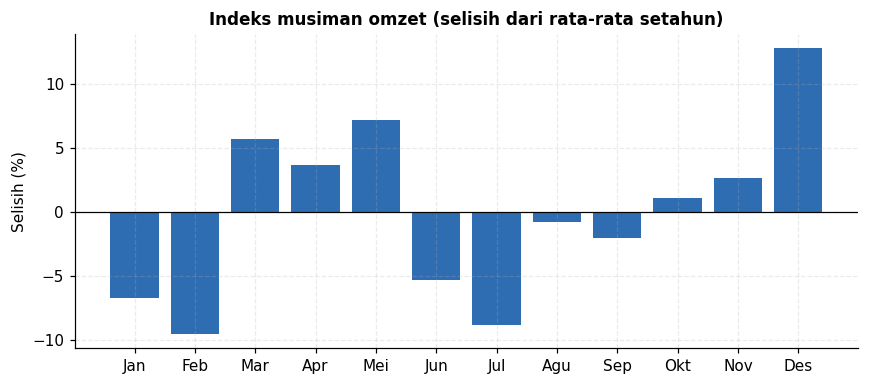

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
nama_bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]
ax.bar(range(1, 13), (musiman["omzet"] - 1) * 100, color=PALET["biru"])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(1, 13), nama_bulan)
ax.set_title("Indeks musiman omzet (selisih dari rata-rata setahun)")
ax.set_ylabel("Selisih (%)")
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "forecast_musiman.png")
plt.show()

## 2. Fungsi model peramalan

Enam model individu dan satu ensambel:

| Kode | Cara kerja | Peran |
|---|---|---|
| `naive_seasonal` | nilai bulan yang sama tahun lalu | baseline wajib |
| `ets` | Holt-Winters: tren meredam + musim aditif | kandidat utama |
| `ets_48` | ETS hanya pada 48 bulan terakhir | uji perubahan rezim |
| `sarima` | SARIMA musiman, orde dipilih AIC | kandidat utama |
| `regresi_musiman` | tren linear + dummy bulan | pembanding yang mudah dijelaskan |
| `xgboost_lag` | lag 1–12 + rata-rata bergerak + bulan | opsi nonlinier |
| `ensamble` | rata-rata ETS dan SARIMA | opsi stabil |

Interval ETS diambil dari simulasi 400 jalur; SARIMA dan regresi memakai interval analitik;
XGBoost memakai simpangan sisa yang melebar mengikuti horizon.

In [6]:
ORIGIN = pd.date_range("2025-05-31", "2026-04-30", freq="ME")
HORIZON_UJI = 6
HORIZON_RAMAL = 12
TAHUN_UJI_SARIMA = seri.loc[:"2025-04-30"]


def ramalan_naive_seasonal(train: pd.Series, h: int) -> dict:
    nilai = train.to_numpy(dtype=float)
    rata = np.array([nilai[-12 + i] for i in range(h)], dtype=float)
    sisa = (train - train.shift(12)).dropna()
    sigma = sisa.std()
    langkah = np.sqrt(1 + np.arange(h) / 12)
    return {
        "rata": rata,
        "lo80": rata - 1.2816 * sigma * langkah,
        "hi80": rata + 1.2816 * sigma * langkah,
        "lo95": rata - 1.96 * sigma * langkah,
        "hi95": rata + 1.96 * sigma * langkah,
    }


def _ets_interval(res, h: int) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
    np.random.seed(SEED)
    simulasi = res.simulate(h, repetitions=400, error="add")
    lo80, hi80 = np.quantile(simulasi.to_numpy(), [0.10, 0.90], axis=1)
    lo95, hi95 = np.quantile(simulasi.to_numpy(), [0.025, 0.975], axis=1)
    return lo80, hi80, lo95, hi95


def ramalan_ets(train: pd.Series, h: int, jendela: int | None = None) -> dict:
    y = train.iloc[-jendela:] if jendela else train
    try:
        model = ExponentialSmoothing(
            y, trend="add", damped_trend=True, seasonal="add",
            seasonal_periods=12, initialization_method="estimated",
        )
        res = model.fit(optimized=True)
    except Exception:
        model = ExponentialSmoothing(y, trend="add", damped_trend=True, seasonal=None)
        res = model.fit(optimized=True)
    rata = res.forecast(h).to_numpy(dtype=float)
    try:
        lo80, hi80, lo95, hi95 = _ets_interval(res, h)
    except Exception:
        sisa = (y - res.fittedvalues).std()
        langkah = np.sqrt(np.arange(1, h + 1))
        lo80 = rata - 1.2816 * sisa * langkah
        hi80 = rata + 1.2816 * sisa * langkah
        lo95 = rata - 1.96 * sisa * langkah
        hi95 = rata + 1.96 * sisa * langkah
    return {"rata": rata, "lo80": lo80, "hi80": hi80, "lo95": lo95, "hi95": hi95}


def pilih_orde_sarima(train: pd.Series) -> tuple[tuple, tuple]:
    terbaik = None
    for p in range(3):
        for q in range(3):
            for P in range(2):
                for Q in range(2):
                    for D in (0, 1):
                        try:
                            res = SARIMAX(
                                train, order=(p, 1, q), seasonal_order=(P, D, Q, 12),
                                trend="c", enforce_stationarity=False, enforce_invertibility=False,
                            ).fit(disp=False)
                            if np.isfinite(res.aic) and (terbaik is None or res.aic < terbaik[0]):
                                terbaik = (res.aic, (p, 1, q), (P, D, Q, 12))
                        except Exception:
                            continue
    if terbaik is None:
        return (1, 1, 1), (0, 1, 1, 12)
    return terbaik[1], terbaik[2]


def ramalan_sarima(train: pd.Series, h: int, orde: tuple, orde_musim: tuple) -> dict:
    res = SARIMAX(
        train, order=orde, seasonal_order=orde_musim, trend="c",
        enforce_stationarity=False, enforce_invertibility=False,
    ).fit(disp=False)
    ramal = res.get_forecast(h)
    interval80 = ramal.conf_int(alpha=0.2)
    interval95 = ramal.conf_int(alpha=0.05)
    return {
        "rata": ramal.predicted_mean.to_numpy(dtype=float),
        "lo80": interval80.iloc[:, 0].to_numpy(dtype=float),
        "hi80": interval80.iloc[:, 1].to_numpy(dtype=float),
        "lo95": interval95.iloc[:, 0].to_numpy(dtype=float),
        "hi95": interval95.iloc[:, 1].to_numpy(dtype=float),
    }


def ramalan_regresi(train: pd.Series, h: int) -> dict:
    n = len(train)
    indeks = train.index
    fitur = pd.DataFrame({"t": np.arange(n)}, index=indeks)
    bulan = pd.get_dummies(indeks.month, prefix="b", drop_first=True).astype(float)
    bulan.index = indeks
    fitur = pd.concat([fitur, bulan], axis=1)
    fitur = sm.add_constant(fitur)
    res = sm.OLS(train.to_numpy(dtype=float), fitur.to_numpy(dtype=float)).fit()

    masa_depan = pd.date_range(indeks[-1] + pd.offsets.MonthEnd(1), periods=h, freq="ME")
    fitur_depan = pd.DataFrame({"t": np.arange(n, n + h)}, index=masa_depan)
    bulan_depan = pd.get_dummies(masa_depan.month, prefix="b", drop_first=True).astype(float)
    bulan_depan.index = masa_depan
    fitur_depan = pd.concat([fitur_depan, bulan_depan], axis=1)
    fitur_depan = fitur_depan.reindex(columns=fitur.columns, fill_value=0.0)
    fitur_depan["const"] = 1.0
    fitur_depan = fitur_depan[fitur.columns]

    interval80 = res.get_prediction(fitur_depan.to_numpy(dtype=float)).summary_frame(alpha=0.2)
    interval95 = res.get_prediction(fitur_depan.to_numpy(dtype=float)).summary_frame(alpha=0.05)
    return {
        "rata": interval80["mean"].to_numpy(dtype=float),
        "lo80": interval80["obs_ci_lower"].to_numpy(dtype=float),
        "hi80": interval80["obs_ci_upper"].to_numpy(dtype=float),
        "lo95": interval95["obs_ci_lower"].to_numpy(dtype=float),
        "hi95": interval95["obs_ci_upper"].to_numpy(dtype=float),
    }


def matriks_lag(nilai: pd.Series, n_lag: int = 12) -> pd.DataFrame:
    tabel = pd.DataFrame({"y": nilai.astype(float)})
    for lag in range(1, n_lag + 1):
        tabel[f"lag_{lag}"] = tabel["y"].shift(lag)
    tabel["rata3"] = tabel["y"].shift(1).rolling(3).mean()
    tabel["rata6"] = tabel["y"].shift(1).rolling(6).mean()
    bulan = pd.get_dummies(nilai.index.month, prefix="b", drop_first=True).astype(float)
    bulan.index = nilai.index
    return pd.concat([tabel, bulan], axis=1).dropna()


def ramalan_xgboost(train: pd.Series, h: int) -> dict:
    data = matriks_lag(train)
    kolom = [k for k in data.columns if k != "y"]
    model = XGBRegressor(
        n_estimators=300, max_depth=2, learning_rate=0.05, subsample=0.9,
        colsample_bytree=0.8, reg_lambda=3.0, random_state=SEED, n_jobs=4,
    )
    model.fit(data[kolom], data["y"])
    sisa = data["y"] - model.predict(data[kolom])
    sigma = float(np.std(sisa))

    riwayat = list(train.to_numpy(dtype=float))
    tanggal = train.index[-1]
    hasil = []
    for i in range(h):
        tanggal = tanggal + pd.offsets.MonthEnd(1)
        baris = {f"lag_{k}": riwayat[-k] for k in range(1, 13)}
        baris["rata3"] = float(np.mean(riwayat[-3:]))
        baris["rata6"] = float(np.mean(riwayat[-6:]))
        for b in range(2, 13):
            baris[f"b_{b}"] = 1.0 if tanggal.month == b else 0.0
        fitur = pd.DataFrame([baris]).reindex(columns=kolom, fill_value=0.0)
        nilai = max(float(model.predict(fitur)[0]), 0.0)
        hasil.append(nilai)
        riwayat.append(nilai)

    rata = np.array(hasil)
    langkah = np.sqrt(np.arange(1, h + 1))
    return {
        "rata": rata,
        "lo80": rata - 1.2816 * sigma * langkah,
        "hi80": rata + 1.2816 * sigma * langkah,
        "lo95": rata - 1.96 * sigma * langkah,
        "hi95": rata + 1.96 * sigma * langkah,
    }

Orde SARIMA dipilih sekali memakai data sampai April 2025, lalu dipakai ulang pada seluruh
backtest. Ini mencegah kebocoran informasi dari masa depan ke pemilihan model.

In [7]:
ORDE_SARIMA = {}
for kolom in seri.columns:
    orde, orde_musim = pilih_orde_sarima(TAHUN_UJI_SARIMA[kolom])
    ORDE_SARIMA[kolom] = (orde, orde_musim)
    print(f"{kolom}: SARIMA{orde}x{orde_musim}")

omzet: SARIMA(1, 1, 2)x(0, 1, 1, 12)


pesanan: SARIMA(1, 1, 2)x(0, 1, 1, 12)


volume: SARIMA(0, 1, 2)x(0, 1, 1, 12)


In [8]:
MODEL = ["naive_seasonal", "ets", "ets_48", "sarima", "regresi_musiman", "xgboost_lag", "ensamble"]


def jalankan_model(nama: str, kolom: str, train: pd.Series, h: int) -> dict:
    if nama == "naive_seasonal":
        hasil = ramalan_naive_seasonal(train, h)
    elif nama == "ets":
        hasil = ramalan_ets(train, h)
    elif nama == "ets_48":
        hasil = ramalan_ets(train, h, jendela=48)
    elif nama == "sarima":
        orde, orde_musim = ORDE_SARIMA[kolom]
        hasil = ramalan_sarima(train, h, orde, orde_musim)
    elif nama == "regresi_musiman":
        hasil = ramalan_regresi(train, h)
    elif nama == "xgboost_lag":
        hasil = ramalan_xgboost(train, h)
    elif nama == "ensamble":
        ets = ramalan_ets(train, h)
        sarima = ramalan_sarima(train, h, *ORDE_SARIMA[kolom])
        hasil = {
            "rata": np.mean([ets["rata"], sarima["rata"]], axis=0),
            "lo80": np.minimum(ets["lo80"], sarima["lo80"]),
            "hi80": np.maximum(ets["hi80"], sarima["hi80"]),
            "lo95": np.minimum(ets["lo95"], sarima["lo95"]),
            "hi95": np.maximum(ets["hi95"], sarima["hi95"]),
        }
    else:
        raise ValueError(nama)
    return hasil

## 3. Backtest 12 origin

Untuk setiap origin (Mei 2025–April 2026), model dilatih hanya dengan data sampai origin itu,
lalu diuji 1–6 bulan ke depan. Semua error digabung per horizon dan per model; model terbaik
dipilih dari WAPE gabungan, bukan dari satu titik uji.

In [9]:
baris_backtest = []
for kolom in seri.columns:
    nilai = seri[kolom]
    for nama in MODEL:
        for origin in ORIGIN:
            posisi = nilai.index.get_loc(origin)
            train = nilai.iloc[: posisi + 1]
            h = min(HORIZON_UJI, len(nilai) - posisi - 1)
            if h <= 0:
                continue
            try:
                hasil = jalankan_model(nama, kolom, train, h)
            except Exception as galat:
                print(f"gagal {kolom}/{nama}/{origin.date()}: {galat}")
                continue
            aktual = nilai.iloc[posisi + 1 : posisi + 1 + h].to_numpy(dtype=float)
            for langkah in range(h):
                baris_backtest.append(
                    {
                        "seri": kolom,
                        "model": nama,
                        "origin": origin,
                        "horizon": langkah + 1,
                        "aktual": aktual[langkah],
                        "prediksi": hasil["rata"][langkah],
                    }
                )

backtest = pd.DataFrame(baris_backtest)
backtest["error"] = backtest["prediksi"] - backtest["aktual"]
backtest["bulan_target"] = backtest["origin"] + pd.to_timedelta(
    (backtest["horizon"] * 30.44).round(), unit="D"
)
simpan(backtest, FORECAST_DIR / "forecast_backtest.csv")
print(f"baris backtest: {len(backtest):,}")


def metrik_error(grup: pd.DataFrame) -> dict:
    aktual = grup["aktual"].to_numpy(dtype=float)
    prediksi = grup["prediksi"].to_numpy(dtype=float)
    error = prediksi - aktual
    return {
        "mae": np.mean(np.abs(error)),
        "rmse": np.sqrt(np.mean(error ** 2)),
        "mape": np.mean(np.abs(error) / np.where(aktual == 0, np.nan, aktual)) * 100,
        "wape": np.sum(np.abs(error)) / np.sum(np.abs(aktual)) * 100,
        "n_obs": len(grup),
    }


baris_metrik = []
for (kolom, nama), grup in backtest.groupby(["seri", "model"]):
    gabungan = metrik_error(grup)
    baris_metrik.append({"seri": kolom, "model": nama, "horizon": "semua", **gabungan})
    for horizon, sub in grup.groupby("horizon"):
        baris_metrik.append({"seri": kolom, "model": nama, "horizon": int(horizon), **metrik_error(sub)})

tabel_error = pd.DataFrame(baris_metrik)
simpan(tabel_error, FORECAST_DIR / "forecast_metrics.csv")

rekomendasi = (
    tabel_error[tabel_error["horizon"] == "semua"]
    .sort_values(["seri", "wape", "mae"])
    .groupby("seri")
    .head(1)
    .set_index("seri")["model"]
    .to_dict()
)
tabel_rekomendasi = pd.DataFrame(
    [
        {
            "seri": kolom,
            "model": nama,
            "wape_semua": float(
                tabel_error[
                    (tabel_error["seri"] == kolom)
                    & (tabel_error["model"] == nama)
                    & (tabel_error["horizon"] == "semua")
                ]["wape"].iloc[0]
            ),
            "mae_semua": float(
                tabel_error[
                    (tabel_error["seri"] == kolom)
                    & (tabel_error["model"] == nama)
                    & (tabel_error["horizon"] == "semua")
                ]["mae"].iloc[0]
            ),
            "is_recommended": True,
        }
        for kolom, nama in rekomendasi.items()
    ]
)
print(rekomendasi)
tabel_rekomendasi

  tersimpan: data\processed\forecast\forecast_backtest.csv (1,512 baris)
baris backtest: 1,512
  tersimpan: data\processed\forecast\forecast_metrics.csv (147 baris)
{'omzet': 'sarima', 'pesanan': 'sarima', 'volume': 'ensamble'}


,seri,model,wape_semua,mae_semua,is_recommended
0,omzet,sarima,8.56,"35,658,164.08",True
1,pesanan,sarima,7.02,4.86,True
2,volume,ensamble,27.88,"1,787.92",True


In [10]:
peringkat = tabel_error[tabel_error["horizon"] == "semua"].copy()
peringkat["peringkat"] = peringkat.groupby("seri")["wape"].rank(method="min")
peringkat["is_recommended"] = [
    bool(peringkat.loc[i, "model"] == rekomendasi[peringkat.loc[i, "seri"]]) for i in peringkat.index
]
simpan(
    peringkat[["seri", "model", "wape", "mae", "rmse", "mape", "peringkat", "is_recommended"]],
    FORECAST_DIR / "forecast_recommendation.csv",
)
peringkat[peringkat["seri"] == "omzet"].sort_values("wape").round(2)

  tersimpan: data\processed\forecast\forecast_recommendation.csv (21 baris)


,seri,model,horizon,mae,rmse,mape,wape,n_obs,peringkat,is_recommended
35,omzet,sarima,semua,"35,658,164.08","45,652,618.51",8.56,8.56,72,1.00,True
0,omzet,ensamble,semua,"40,480,323.49","54,192,469.57",9.61,9.72,72,2.00,False
14,omzet,ets_48,semua,"48,574,127.52","64,644,465.03",11.80,11.66,72,3.00,False
7,omzet,ets,semua,"49,004,746.62","66,988,239.78",11.63,11.76,72,4.00,False
21,omzet,naive_seasonal,semua,"57,069,042.67","68,020,876.92",14.08,13.70,72,5.00,False
42,omzet,xgboost_lag,semua,"70,454,333.54","80,843,653.42",17.90,16.91,72,6.00,False
28,omzet,regresi_musiman,semua,"114,663,858.08","121,878,117.28",29.02,27.53,72,7.00,False


## 4. Perbandingan model

Grafik ini yang paling mudah dipakai di Halaman 2: dashboard dapat menampilkan seluruh model
sekaligus, dengan model rekomendasi ditandai.

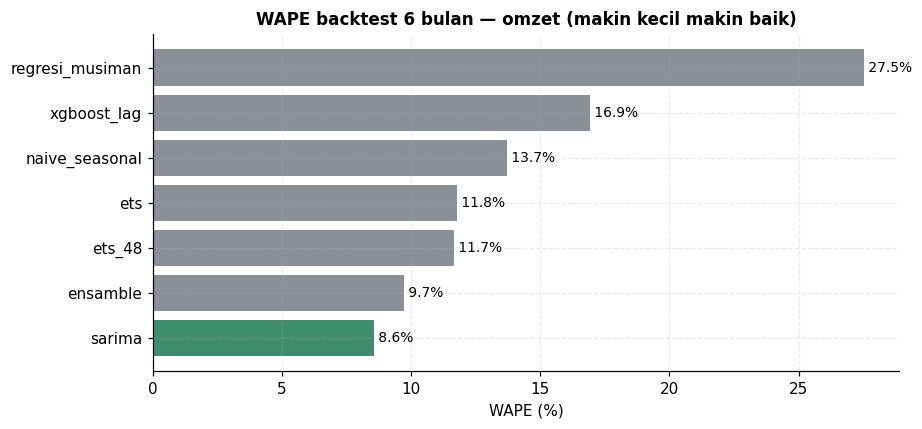

In [11]:
fig, ax = plt.subplots(figsize=(8.5, 4))
data_omzet = peringkat[peringkat["seri"] == "omzet"].sort_values("wape")
warna = [PALET["hijau"] if r else PALET["abu"] for r in data_omzet["is_recommended"]]
ax.barh(data_omzet["model"], data_omzet["wape"], color=warna)
for i, v in enumerate(data_omzet["wape"]):
    ax.text(v, i, f" {v:.1f}%", va="center", fontsize=9)
ax.set_title("WAPE backtest 6 bulan — omzet (makin kecil makin baik)")
ax.set_xlabel("WAPE (%)")
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "forecast_perbandingan_model.png")
plt.show()

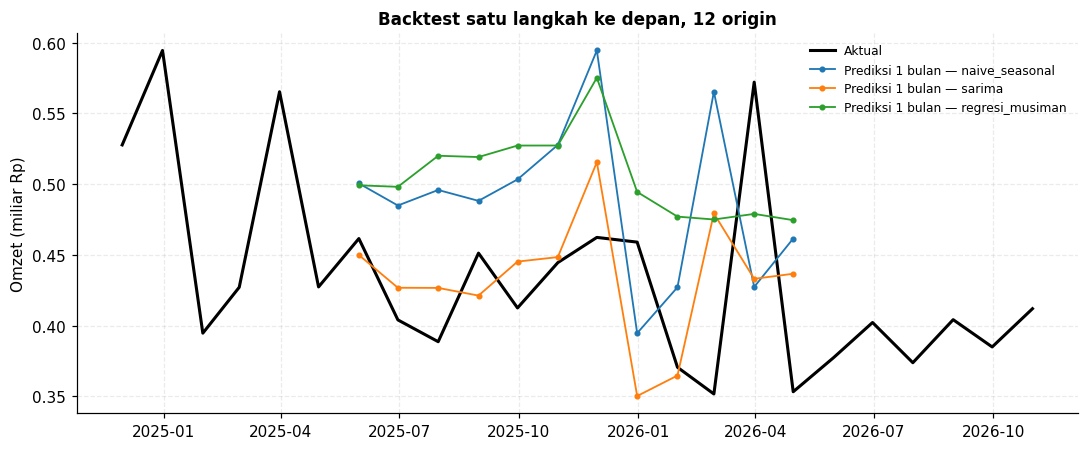

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.2))
aktual = seri.loc["2024-11-30":, "omzet"] / 1e9
ax.plot(aktual.index, aktual, color="black", linewidth=2, label="Aktual")
for nama in dict.fromkeys(["naive_seasonal", rekomendasi["omzet"], "regresi_musiman"]):
    subset = backtest[
        (backtest["seri"] == "omzet") & (backtest["model"] == nama) & (backtest["horizon"] == 1)
    ].sort_values("origin")
    ax.plot(subset["origin"], subset["prediksi"] / 1e9, marker="o", markersize=3,
            linewidth=1.2, label=f"Prediksi 1 bulan — {nama}")
ax.set_title("Backtest satu langkah ke depan, 12 origin")
ax.set_ylabel("Omzet (miliar Rp)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "forecast_backtest.png")
plt.show()

## 5. Ramalan 12 bulan ke depan

Seluruh model dilatih ulang pada 94 bulan data, lalu meramal November 2026–Oktober 2027.
Tampilan yang disarankan untuk dashboard adalah **6 bulan pertama**; bulan ke-7 sampai ke-12
tetap disediakan tetapi belum bisa divalidasi.

In [13]:
masa_depan = pd.date_range(seri.index[-1] + pd.offsets.MonthEnd(1), periods=HORIZON_RAMAL, freq="ME")
baris_ramal = []

for kolom in seri.columns:
    for bulan, nilai in seri[kolom].items():
        baris_ramal.append(
            {"seri": kolom, "model": "aktual", "bulan": bulan, "jenis": "aktual",
             "nilai": float(nilai), "lo80": np.nan, "hi80": np.nan, "lo95": np.nan,
             "hi95": np.nan, "horizon_ke": np.nan, "is_recommended": False}
        )
    for nama in MODEL:
        hasil = jalankan_model(nama, kolom, seri[kolom], HORIZON_RAMAL)
        for i, bulan in enumerate(masa_depan):
            baris_ramal.append(
                {
                    "seri": kolom, "model": nama, "bulan": bulan, "jenis": "prediksi",
                    "nilai": float(hasil["rata"][i]),
                    "lo80": float(hasil["lo80"][i]), "hi80": float(hasil["hi80"][i]),
                    "lo95": float(hasil["lo95"][i]), "hi95": float(hasil["hi95"][i]),
                    "horizon_ke": i + 1,
                    "is_recommended": bool(nama == rekomendasi[kolom]),
                }
            )

ramalan = pd.DataFrame(baris_ramal)
simpan(ramalan, FORECAST_DIR / "forecast_values.csv")

ramalan_omzet = ramalan[
    (ramalan["seri"] == "omzet")
    & (ramalan["model"].isin(["aktual", rekomendasi["omzet"]]))
].copy()
ramalan_omzet.tail(14).round(0)

  tersimpan: data\processed\forecast\forecast_values.csv (534 baris)


,seri,model,bulan,jenis,nilai,lo80,hi80,lo95,hi95,horizon_ke,is_recommended
92,omzet,aktual,2026-09-30,aktual,"385,024,942.00",NaN,NaN,NaN,NaN,NaN,False
93,omzet,aktual,2026-10-31,aktual,"412,055,455.00",NaN,NaN,NaN,NaN,NaN,False
130,omzet,sarima,2026-11-30,prediksi,"431,348,553.00","360,197,534.00","502,499,571.00","322,532,460.00","540,164,645.00",1.00,True
131,omzet,sarima,2026-12-31,prediksi,"444,281,108.00","372,542,085.00","516,020,132.00","334,565,740.00","553,996,477.00",2.00,True
132,omzet,sarima,2027-01-31,prediksi,"338,251,677.00","260,643,584.00","415,859,770.00","219,560,341.00","456,943,013.00",3.00,True
133,omzet,sarima,2027-02-28,prediksi,"330,949,326.00","250,060,173.00","411,838,480.00","207,240,042.00","454,658,611.00",4.00,True
134,omzet,sarima,2027-03-31,prediksi,"530,195,793.00","445,511,370.00","614,880,216.00","400,682,144.00","659,709,441.00",5.00,True
135,omzet,sarima,2027-04-30,prediksi,"344,143,393.00","256,037,480.00","432,249,306.00","209,397,027.00","478,889,760.00",6.00,True
136,omzet,sarima,2027-05-31,prediksi,"363,293,806.00","271,827,396.00","454,760,217.00","223,408,003.00","503,179,610.00",7.00,True
137,omzet,sarima,2027-06-30,prediksi,"374,233,339.00","279,547,197.00","468,919,481.00","229,423,381.00","519,043,297.00",8.00,True


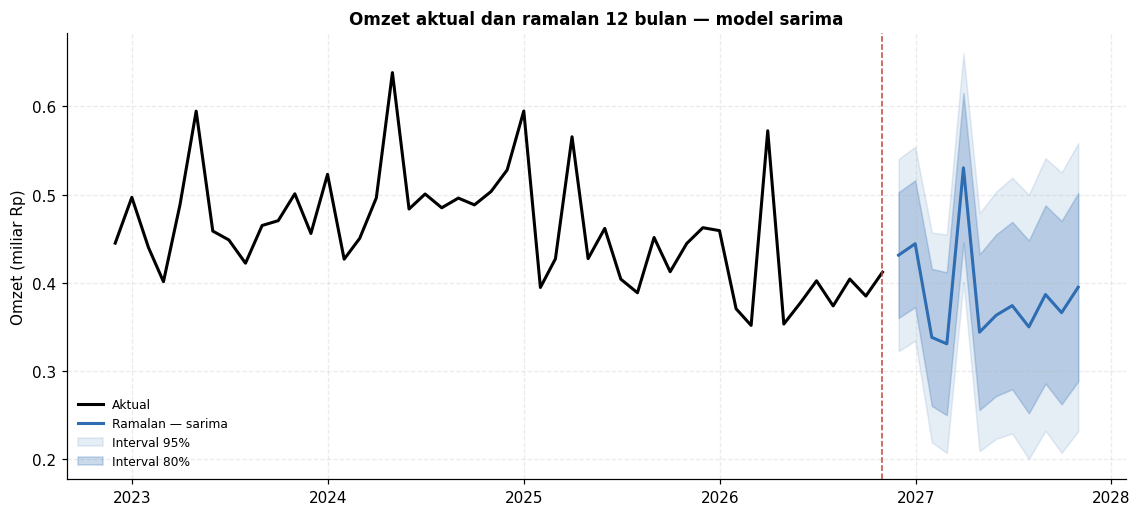

In [14]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
historis = ramalan[(ramalan["seri"] == "omzet") & (ramalan["model"] == "aktual")].tail(48)
pilihan = ramalan[(ramalan["seri"] == "omzet") & (ramalan["model"] == rekomendasi["omzet"])]

ax.plot(historis["bulan"], historis["nilai"] / 1e9, color="black", linewidth=2, label="Aktual")
ax.plot(pilihan["bulan"], pilihan["nilai"] / 1e9, color=PALET["biru"], linewidth=2,
        label=f"Ramalan — {rekomendasi['omzet']}")
ax.fill_between(pilihan["bulan"], pilihan["lo95"] / 1e9, pilihan["hi95"] / 1e9,
                color=PALET["biru"], alpha=0.12, label="Interval 95%")
ax.fill_between(pilihan["bulan"], pilihan["lo80"] / 1e9, pilihan["hi80"] / 1e9,
                color=PALET["biru"], alpha=0.25, label="Interval 80%")
ax.axvline(seri.index[-1], color=PALET["merah"], linestyle="--", linewidth=1)
ax.set_title(f"Omzet aktual dan ramalan 12 bulan — model {rekomendasi['omzet']}")
ax.set_ylabel("Omzet (miliar Rp)")
ax.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.savefig(GAMBAR_DIR / "forecast_aktual_prediksi.png")
plt.show()

## 6. Skenario retensi (menyambungkan model churn)

Angka ini bukan prediksi model time-series, melainkan skenario sederhana: berapa tambahan omzet
12 bulan jika sebagian pelanggan berisiko tinggi berhasil dipertahankan. Asumsinya pelanggan yang
dipertahankan berbelanja seperti rata-rata pelanggan aktif (memakai omzet 12 bulan terakhir).

In [15]:
skor_churn = AKAR_NOTEBOOK / "data" / "processed" / "churn" / "churn_scores.csv"
baris_skenario = []
if skor_churn.exists():
    skor = pd.read_csv(skor_churn)
    aktif = skor[skor["status"] == "Aktif"]
    risiko_tinggi = aktif[aktif["band_kuantil"] == "Tinggi"]
    omzet_rata_aktif = aktif["omzet_12"].mean()
    total_ramal_12 = pilihan["nilai"].sum()
    for persen in (0.10, 0.20, 0.30):
        dipertahankan = int(round(len(risiko_tinggi) * persen))
        tambahan = dipertahankan * omzet_rata_aktif
        baris_skenario.append(
            {
                "skenario": f"Pertahankan {int(persen*100)}% pelanggan berisiko tinggi",
                "asumsi": "pelanggan yang dipertahankan berbelanja seperti rata-rata pelanggan aktif",
                "pelanggan_berisiko": len(risiko_tinggi),
                "pelanggan_dipertahankan": dipertahankan,
                "omzet_rata_per_pelanggan_12_bulan": omzet_rata_aktif,
                "tambahan_omzet_12_bulan": tambahan,
                "total_dengan_skenario": total_ramal_12 + tambahan,
            }
        )
    simpan(pd.DataFrame(baris_skenario), FORECAST_DIR / "forecast_scenario.csv")
    pd.DataFrame(baris_skenario).round(0)
else:
    print("churn_scores.csv belum ada, skenario dilewati")

  tersimpan: data\processed\forecast\forecast_scenario.csv (3 baris)


## 7. Ringkasan keluaran

| Berkas | Isi |
|---|---|
| `forecast_values.csv` | long format: seri × model × bulan, aktual/prediksi + interval |
| `forecast_metrics.csv` | MAE, RMSE, MAPE, WAPE per model dan horizon |
| `forecast_recommendation.csv` | peringkat model + penanda rekomendasi per seri |
| `forecast_backtest.csv` | aktual vs prediksi pada 12 origin |
| `forecast_seasonality.csv` | indeks musiman per bulan |
| `forecast_scenario.csv` | skenario retensi pelanggan berisiko |

**Batas tafsir:** hanya 94 bulan data dan ada perubahan rezim 2024–2026. Ramalan 12 bulan
menunjukkan arah dan ketidakpastian, bukan target pasti. Model nonlinier (XGBoost) paling rawan
overfit pada deret pendek; karena itu baseline dan model sederhana selalu ikut dibandingkan.

In [16]:
ringkasan_ramal = {}
for kolom in seri.columns:
    nama = rekomendasi[kolom]
    sub = ramalan[
        (ramalan["seri"] == kolom) & (ramalan["model"] == nama) & (ramalan["jenis"] == "prediksi")
    ]
    nilai6 = sub[sub["horizon_ke"] <= 6]["nilai"].sum()
    nilai12 = sub["nilai"].sum()
    ringkasan_ramal[kolom] = {
        "model": nama,
        "wape_backtest": float(
            tabel_error[
                (tabel_error["seri"] == kolom)
                & (tabel_error["model"] == nama)
                & (tabel_error["horizon"] == "semua")
            ]["wape"].iloc[0]
        ),
        "ramalan_6_bulan": float(nilai6),
        "ramalan_12_bulan": float(nilai12),
        "ramalan_6_bulan_rupiah": rupiah(nilai6) if kolom == "omzet" else f"{nilai6:,.0f}",
        "ramalan_12_bulan_rupiah": rupiah(nilai12) if kolom == "omzet" else f"{nilai12:,.0f}",
    }
ringkasan_ramal

{'omzet': {'model': 'sarima',
  'wape_backtest': 8.56012575689003,
  'ramalan_6_bulan': 2419169850.380884,
  'ramalan_12_bulan': 4654872710.985412,
  'ramalan_6_bulan_rupiah': 'Rp 2.42 M',
  'ramalan_12_bulan_rupiah': 'Rp 4.65 M'},
 'pesanan': {'model': 'sarima',
  'wape_backtest': 7.022462970189669,
  'ramalan_6_bulan': 268.5266619103565,
  'ramalan_12_bulan': 457.8785332787572,
  'ramalan_6_bulan_rupiah': '269',
  'ramalan_12_bulan_rupiah': '458'},
 'volume': {'model': 'ensamble',
  'wape_backtest': 27.880029461842152,
  'ramalan_6_bulan': 33836.25526184082,
  'ramalan_12_bulan': 63449.34511013205,
  'ramalan_6_bulan_rupiah': '33,836',
  'ramalan_12_bulan_rupiah': '63,449'}}

## 8. Temuan

- **SARIMA** terbaik untuk omzet: WAPE 8,56% dan MAE Rp 35,7 juta pada backtest 6 bulan;
  baseline seasonal naive 13,70%. Untuk pesanan SARIMA juga terbaik (WAPE 7,02%); untuk volume
  ensambel (WAPE 27,88%) — volume paling sulit diprediksi.
- Model nonlinier **XGBoost kalah** (WAPE 16,91%) karena deret hanya 94 titik, sedangkan
  **regresi linear paling buruk** (27,53%) karena tren berbalik pada 2024–2026 dan model
  mengekstrapolasi pertumbuhan lama.
- Ramalan omzet **6 bulan Rp 2,42 miliar** dan **12 bulan Rp 4,66 miliar** (Nov 2026–Okt 2027).
  Contoh: November 2026 diprediksi Rp 431 juta dengan interval 80% Rp 360–502 juta.
- Interval melebar cepat setelah 6 bulan, jadi dashboard sebaiknya menonjolkan horizon pendek.
- **Skenario retensi:** mempertahankan 20% dari 14 pelanggan berisiko tinggi (3 pelanggan)
  menambah sekitar Rp 216 juta omzet 12 bulan, menaikkan total menjadi Rp 4,87 miliar.

**Batas tafsir:** hanya 94 bulan data, ada perubahan rezim, dan 2026 baru 10 bulan. Ramalan
menunjukkan arah dan ketidakpastian, bukan target pasti.
